In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets
from torchvision.transforms import v2   # 导入v2
from torch.utils.data import DataLoader
import time

# ===== 这里换成v2，不再用ToTensor！=====
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 512),
            nn.ReLU(),
            nn.Linear(512, 10)
        )
    def forward(self, x):
        return self.net(x)


In [2]:
def train_loop(model, device, epochs=6, batch_size=64, lr=1e-3):
    train_dataset = datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)
    val_dataset = datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    train_loss_list = []
    val_loss_list = []
    val_acc_list = []

    start_time = time.time()
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * images.size(0)
        train_loss = running_loss / len(train_loader.dataset)
        train_loss_list.append(train_loss)

        model.eval()
        val_running_loss = 0.0
        correct = 0
        total = 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                val_running_loss += loss.item() * images.size(0)
                _, pred = torch.max(outputs, 1)
                total += labels.size(0)
                correct += (pred == labels).sum().item()
        val_loss = val_running_loss / len(val_loader.dataset)
        val_acc = correct / total * 100
        val_loss_list.append(val_loss)
        val_acc_list.append(val_acc)

        print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%")

    end_time = time.time()
    total_time = end_time - start_time
    print(f"本轮总耗时: {total_time:.2f} s")
    return model, train_loss_list, val_loss_list, val_acc_list, total_time


In [3]:
device_gpu = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device_cpu = torch.device("cpu")

print("===== GPU训练 =====")
model_gpu = SimpleCNN()
model_gpu, gpu_train_loss, gpu_val_loss, gpu_val_acc, time_gpu = train_loop(model_gpu, device_gpu, epochs=6)

print("\n===== CPU训练 =====")
model_cpu = SimpleCNN()
model_cpu, cpu_train_loss, cpu_val_loss, cpu_val_acc, time_cpu = train_loop(model_cpu, device_cpu, epochs=6)

print("\ngpu_train_loss =", gpu_train_loss)
print("gpu_val_loss   =", gpu_val_loss)
print("gpu_val_acc    =", gpu_val_acc)
print("time_gpu =", time_gpu)

print("\ncpu_train_loss =", cpu_train_loss)
print("cpu_val_loss   =", cpu_val_loss)
print("cpu_val_acc    =", cpu_val_acc)
print("time_cpu =", time_cpu)


===== GPU训练 =====
Epoch [1/6] | Train Loss: 1.3110 | Val Loss: 0.9540 | Val Acc: 65.92%
Epoch [2/6] | Train Loss: 0.8585 | Val Loss: 0.8143 | Val Acc: 71.72%
Epoch [3/6] | Train Loss: 0.6748 | Val Loss: 0.7864 | Val Acc: 72.88%
Epoch [4/6] | Train Loss: 0.5324 | Val Loss: 0.7937 | Val Acc: 72.95%
Epoch [5/6] | Train Loss: 0.4159 | Val Loss: 0.7473 | Val Acc: 76.40%
Epoch [6/6] | Train Loss: 0.3152 | Val Loss: 0.8446 | Val Acc: 75.09%
本轮总耗时: 55.35 s

===== CPU训练 =====
Epoch [1/6] | Train Loss: 1.3154 | Val Loss: 0.9773 | Val Acc: 65.67%
Epoch [2/6] | Train Loss: 0.8576 | Val Loss: 0.8506 | Val Acc: 70.27%
Epoch [3/6] | Train Loss: 0.6675 | Val Loss: 0.7401 | Val Acc: 74.50%
Epoch [4/6] | Train Loss: 0.5241 | Val Loss: 0.7439 | Val Acc: 74.47%
Epoch [5/6] | Train Loss: 0.4015 | Val Loss: 0.7617 | Val Acc: 75.86%
Epoch [6/6] | Train Loss: 0.2920 | Val Loss: 0.8721 | Val Acc: 74.62%
本轮总耗时: 141.19 s

gpu_train_loss = [1.3109538502502442, 0.8585094024658203, 0.6748281616210937, 0.53240826429

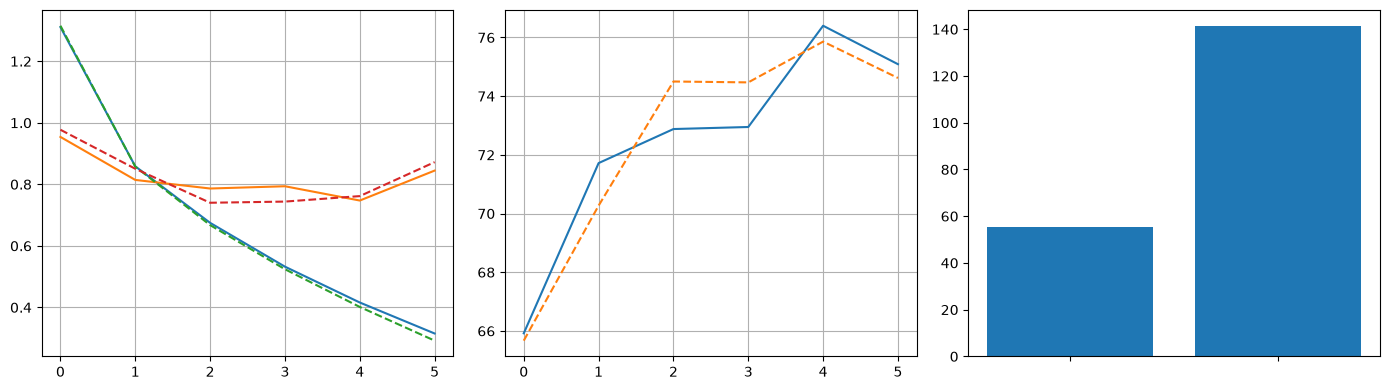

GPU耗时：55.35 s
CPU耗时：141.19 s
CPU/GPU 耗时倍数：2.55


In [4]:
import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
plt.plot(gpu_train_loss)
plt.plot(gpu_val_loss)
plt.plot(cpu_train_loss, linestyle="--")
plt.plot(cpu_val_loss, linestyle="--")
plt.grid(True)

plt.subplot(1, 3, 2)
plt.plot(gpu_val_acc)
plt.plot(cpu_val_acc, linestyle="--")
plt.grid(True)

plt.subplot(1, 3, 3)
plt.bar([0, 1], [time_gpu, time_cpu])
plt.xticks([0, 1], ["", ""])

plt.tight_layout()
plt.show()

print(f"GPU耗时：{time_gpu:.2f} s")
print(f"CPU耗时：{time_cpu:.2f} s")
print(f"CPU/GPU 耗时倍数：{time_cpu / time_gpu:.2f}")
